# Projeto 2 — Reinforcement Learning no Taxi-v4: Q-learning vs SARSA (ambientes determinístico e não determinístico)

**Disciplina:** Inteligência Artificial — Insper · **Entrega:** 04/11/2026

Neste notebook treinamos agentes de **Q-learning** e **SARSA** no ambiente `Taxi-v4` do Gymnasium, primeiro em sua versão
determinística e depois na versão não determinística (`is_rainy=True, rainy_probability=0.6`), e comparamos eficiência de aprendizado
e desempenho final.

**Organização**

| Seção | Conteúdo | Itens do enunciado |
|---|---|---|
| 0 | Conceitos, ambiente e referência ótima | — |
| 1 | Escolha dos hiperparâmetros | "valores de hiperparâmetros que possibilitem aprendizado rápido e eficiente" |
| 2 | Q-learning no ambiente determinístico: 5 treinos + curva de aprendizado + 100 execuções | 1 e 2 |
| 3 | SARSA no ambiente determinístico (mesmas análises) | 2 (repetição) |
| 4 | Q-learning vs SARSA | 3 |
| 5 | Ambiente não determinístico: transferência da Q-table, treino no ambiente chuvoso, comparações | 4 e 5 |
| 6 | Resumo geral e conclusões | Entrega |

**Código:** toda a lógica (ambiente, treino, avaliação, value iteration) está em [`rl_taxi.py`](rl_taxi.py); este notebook chama essas funções,
roda os experimentos e discute os resultados. Todos os experimentos usam *seeds* fixas, então os números abaixo são reproduzíveis
(`jupyter nbconvert --to notebook --execute --inplace projeto2_taxi_qlearning_sarsa.ipynb`).

## 0. Conceitos, ambiente e referência ótima

### 0.1 O ciclo de reinforcement learning
O **agente** observa um **estado** $s$, escolhe uma **ação** $a$, e o **ambiente** devolve um **reward** $r$ e o próximo estado $s'$.
O agente não recebe instruções de como resolver a tarefa; ele só aprende, por tentativa e erro, quais ações levam ao maior reward **acumulado**.
Um **episódio** é uma tentativa completa (do início até o fim da tarefa ou até o limite de passos). A **política** $\pi(s)$ é a regra "em tal estado, faça tal ação".

### 0.2 O ambiente Taxi-v4
* Grade 5×5 com 4 pontos de embarque/desembarque: **R**(0, 0), **G**(0, 4), **Y**(4, 0), **B**(4, 3), e algumas paredes.
* O passageiro começa em um dos 4 pontos e quer ir para outro (destino). O táxi precisa ir até ele, **pegar**, levar até o destino e **deixar**.
* **Estados:** $25 \text{ posições do táxi} \times 5 \text{ posições do passageiro (4 pontos + dentro do táxi)} \times 4 \text{ destinos} = 500$ estados (números de 0 a 499).
  Destes, 300 são estados iniciais possíveis (passageiro num ponto e destino diferente da origem).
* **Ações (6):** 0 Sul · 1 Norte · 2 Leste · 3 Oeste · 4 Pegar · 5 Deixar.
* **Rewards:** **−1** por passo · **+20** ao deixar o passageiro no destino (fim do episódio) · **−10** por pegar/deixar em local ilegal.
* O episódio é cortado em **200 passos** (*truncation*).
* Como o reward por passo é −1, o reward de um episódio bem-sucedido é $21 - \text{timesteps}$ (cada passo custa 1 e o último passo, em vez de −1, rende +20).
  Ou seja, **menos timesteps = mais reward**.

### 0.3 Q-table, Q-learning e SARSA
A **Q-table** $Q(s,a)$ guarda uma estimativa do reward futuro acumulado de tomar a ação $a$ no estado $s$ e seguir bem dali em diante.
Aqui ela é uma matriz 500×6. A política **gulosa** é $\pi(s)=\arg\max_a Q(s,a)$.

Depois de cada passo $(s, a, r, s')$ atualizamos:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[\,\text{alvo} - Q(s,a)\,\big]$$

| Algoritmo | Alvo | Tipo |
|---|---|---|
| **Q-learning** | $r + \gamma \max_{a'} Q(s',a')$ | *off-policy*: aprende o valor da política **ótima**, mesmo explorando |
| **SARSA** | $r + \gamma\, Q(s',a')$, com $a'$ a ação que **de fato** será tomada | *on-policy*: aprende o valor da política que está **executando** (inclusive a exploração) |

Se o episódio terminou (passageiro entregue) não há futuro e o alvo é só $r$. A **única** diferença entre os dois algoritmos no código é essa linha do alvo.

### 0.4 Exploração (ε-greedy) e hiperparâmetros
Com probabilidade $\varepsilon$ o agente age aleatoriamente (explora); senão escolhe $\arg\max_a Q(s,a)$ (explota).
Começamos com $\varepsilon=1$ e o reduzimos a cada episódio ($\varepsilon \leftarrow \max(\varepsilon_{\min}, \varepsilon\cdot\text{decay})$): no início explora-se muito, depois quase só se explota.
Hiperparâmetros: taxa de aprendizado $\alpha$, desconto $\gamma$, e o cronograma de $\varepsilon$.

### 0.5 Ambiente não determinístico
Com `is_rainy=True` e `rainy_probability=0.6`, ao pedir uma ação de movimento (Sul/Norte/Leste/Oeste) o táxi se move na direção pedida com probabilidade
**0.6** e desliza para cada lado perpendicular com probabilidade **0.2** (pegar/deixar continuam determinísticos). Isso introduz incerteza: a **mesma ação** no **mesmo estado** pode levar a resultados diferentes,
e o agente precisa aprender uma política robusta que maximize o reward **esperado**.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from scipy import stats

import rl_taxi as rl
from rl_taxi import (HParams, make_env, train, run_many, evaluate, value_iteration,
                     moving_average, episodes_to_goal, ACTION_NAMES)

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
pd.options.display.float_format = "{:,.2f}".format
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

# estilo dos gráficos: fundo claro, grade discreta; cores fixas por agente
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8985", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
C_Q, C_S, C_OPT = "#2a78d6", "#eb6834", "#6b6a66"   # Q-learning (azul), SARSA (laranja), ótimo (cinza)

print("gymnasium", gym.__version__, "| numpy", np.__version__, "| python", sys.version.split()[0])

gymnasium 1.4.0 | numpy 2.3.2 | python 3.13.7


### 0.6 Conhecendo o ambiente

In [2]:
env = make_env(rainy=False, render_mode="ansi")
print("Espaço de estados :", env.observation_space)
print("Espaço de ações   :", env.action_space, "->", ACTION_NAMES)
print("Limite de passos  :", env.spec.max_episode_steps)

s, _ = env.reset(seed=0)
row, col, pas, dest = env.unwrapped.decode(s)
print(f"\nEstado inicial {s} = táxi na linha {row}, coluna {col} | passageiro em {pas} | destino {dest}  (0=R, 1=G, 2=Y, 3=B, 4=no táxi)")
print(env.render())

Espaço de estados : Discrete(500)
Espaço de ações   : Discrete(6) -> ['Sul', 'Norte', 'Leste', 'Oeste', 'Pegar', 'Deixar']
Limite de passos  : 200

Estado inicial 314 = táxi na linha 3, coluna 0 | passageiro em 3 | destino 2  (0=R, 1=G, 2=Y, 3=B, 4=no táxi)
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+




Para ver na prática a diferença entre os dois ambientes, comparamos o que acontece ao pedir **Leste** no mesmo estado.
O gymnasium expõe o modelo de transições em `env.unwrapped.P[estado][ação] = [(probabilidade, próximo_estado, reward, terminou), ...]`
(só para inspeção — os agentes **não** usam esse modelo, aprendem apenas interagindo).

In [3]:
e_det, e_rain = make_env(False), make_env(True)
s_demo = e_det.unwrapped.encode(2, 2, 0, 1)    # táxi em (2,2), passageiro em R, destino G
def show(env_, nome):
    rows = []
    for p, s2, r, t in env_.unwrapped.P[s_demo][2]:          # ação 2 = Leste
        rr, cc, _, _ = env_.unwrapped.decode(s2)
        rows.append({"ambiente": nome, "prob.": p, "táxi vai para (linha, col)": (rr, cc), "reward": r})
    return pd.DataFrame(rows)
display(pd.concat([show(e_det, "determinístico"), show(e_rain, "chuvoso (0.6)")], ignore_index=True))

,ambiente,prob.,"táxi vai para (linha, col)",reward
0,determinístico,1.00,"(2, 3)",-1
1,chuvoso (0.6),0.60,"(2, 3)",-1
2,chuvoso (0.6),0.20,"(1, 2)",-1
3,chuvoso (0.6),0.20,"(3, 2)",-1


### 0.7 Referência: qual é o reward ótimo?
Para os gráficos precisamos saber **qual é a "meta" de reward acumulado**. O ambiente conhece seu próprio modelo, então resolvemos o problema **exatamente** com *value iteration*
(programação dinâmica; função `value_iteration` em `rl_taxi.py`). Isso **não** é usado para treinar os agentes: serve só como régua.
O valor calculado é o reward médio da política ótima sobre a distribuição de estados iniciais.

> **Observação:** a documentação do gymnasium cita `optimum = 8.46` e `reward_threshold = 8` para o Taxi, mas o ótimo exato calculado aqui é **menor que 8**
> (a média do reward ótimo é $21 - \overline{\text{passos}}$, e o menor número médio de passos possível não é suficiente para chegar a 8).
> Por isso usamos o valor calculado como meta, e não o 8.

In [4]:
V_det,  Qopt_det,  OPT_DET  = value_iteration(rainy=False)
V_rain, Qopt_rain, OPT_RAIN = value_iteration(rainy=True)

print(f"Reward ótimo esperado — determinístico : {OPT_DET:6.3f}   (≈ {21-OPT_DET:5.2f} passos em média)")
print(f"Reward ótimo esperado — chuvoso (0.6)  : {OPT_RAIN:6.3f}   (≈ {21-OPT_RAIN:5.2f} passos em média, ignorando o limite de 200 passos)")

Reward ótimo esperado — determinístico :  7.930   (≈ 13.07 passos em média)
Reward ótimo esperado — chuvoso (0.6)  : -3.962   (≈ 24.96 passos em média, ignorando o limite de 200 passos)


## 1. Escolha dos hiperparâmetros

O enunciado pede hiperparâmetros que permitam aprendizado **rápido e eficiente**, e que sejam os **mesmos** no Q-learning e no SARSA.
Como o Q-learning é o agente de referência, escolhemos os valores olhando para ele.

**Método:** busca em grade com 3 *seeds* por configuração (seeds 0, 1, 2 — **diferentes** das usadas nos experimentos finais, 100–104, para não escolher hiperparâmetros "sob medida" para os resultados reportados),
5000 episódios, nos **dois** ambientes. Para cada configuração medimos:

* `ep_to_goal` — velocidade: 1º episódio em que a média móvel (100 episódios) do reward de treino chega a no máximo 1.5 abaixo do ótimo (7.93 − 1.5 no determinístico; −3.96 − 1.5 no chuvoso); "NaN" = nunca chegou;
* `reward_últimos500` — reward médio de treino nos últimos 500 episódios;
* `eval_passos` e `sucesso` — desempenho da política gulosa final em 1000 execuções (seed de avaliação distinta).

A grade variou $\alpha$ (0.1; 0.3; 0.5), o decaimento de $\alpha$ (nenhum, ou 0.999/0.9995 por episódio até um piso) e o decaimento de $\varepsilon$ (0.99; 0.995). Os resultados estão em `results/` (gerados por `rl_taxi.grid_search`).
Foi feita ainda uma busca anterior (3000 episódios, ambiente determinístico) variando também $\gamma$ (0.9; 0.99), $\alpha$ até 0.9 e decaimento de $\varepsilon$ de 0.999.

In [5]:
RERUN_TUNING = False    # True re-executa a busca (leva vários minutos); False usa os resultados salvos em results/
if RERUN_TUNING:
    import itertools
    hps = [HParams(n_episodes=5000, alpha=a0, alpha_min=amin, alpha_decay=ad, gamma=0.99, eps_decay=ed)
           for a0, amin, ad, ed in itertools.product((0.3, 0.5), (0.02, 0.05), (0.999, 0.9995), (0.99, 0.995))]
    hps += [HParams(n_episodes=5000, alpha=a, gamma=0.99, eps_decay=0.99) for a in (0.1, 0.3)]
    rl.grid_search(hps, ("qlearning", "sarsa"), (0, 1, 2), False, goal=OPT_DET - 1.5).to_csv("results/tuning_det.csv", index=False)
    rl.grid_search(hps, ("qlearning", "sarsa"), (0, 1, 2), True,  goal=OPT_RAIN - 1.5).to_csv("results/tuning_rainy.csv", index=False)

tun_det, tun_rain = pd.read_csv("results/tuning_det.csv"), pd.read_csv("results/tuning_rainy.csv")
KEYS = ["alpha", "alpha_min", "alpha_decay", "eps_decay"]

def resume(df, algo):
    g = df[df.algo == algo].groupby(KEYS).agg(
        ep_to_goal=("ep_to_goal", "mean"), falhas_meta=("ep_to_goal", lambda x: int(x.isna().sum())),
        reward_ult500=("reward_last500", "mean"), eval_passos=("eval_steps", "mean"), sucesso=("eval_success", "mean"))
    return g

def lado_a_lado(algo):
    d, r = resume(tun_det, algo), resume(tun_rain, algo)
    t = d.join(r, lsuffix="_det", rsuffix="_chuva").sort_values("ep_to_goal_det").reset_index()
    t["escolhida"] = np.where((t.alpha == 0.3) & (t.alpha_decay == 1.0) & (t.eps_decay == 0.99), "★", "")
    for c in KEYS:                                   # texto: evita mostrar 0.999 como "1.00"
        t[c] = t[c].map(lambda v: f"{v:g}")
    return t

print("Q-LEARNING — 3 seeds por linha (alpha_min=0 e alpha_decay=1 significam alpha constante)")
display(lado_a_lado("qlearning").style.hide(axis="index").format(precision=2))

Q-LEARNING — 3 seeds por linha (alpha_min=0 e alpha_decay=1 significam alpha constante)


alpha,alpha_min,alpha_decay,eps_decay,ep_to_goal_det,falhas_meta_det,reward_ult500_det,eval_passos_det,sucesso_det,ep_to_goal_chuva,falhas_meta_chuva,reward_ult500_chuva,eval_passos_chuva,sucesso_chuva,escolhida
0.5,0.05,0.999,0.99,558.33,0,7.49,13.27,1.00,1635.67,0,-6.88,27.64,1.00,
0.5,0.02,0.999,0.99,558.33,0,7.47,13.27,1.00,1635.67,0,-6.67,29.45,0.98,
0.5,0.02,0.9995,0.99,596.67,0,7.24,13.40,1.00,2807.33,0,-8.18,27.87,1.00,
0.5,0.05,0.9995,0.99,596.67,0,7.24,13.40,1.00,2807.33,0,-8.18,27.87,1.00,
0.3,0,1,0.99,784.33,0,7.17,13.39,1.00,1871.00,0,-6.42,27.37,1.00,★
0.5,0.02,0.9995,0.995,798.67,0,7.21,13.45,1.00,2247.67,0,-7.38,27.51,1.00,
0.5,0.05,0.9995,0.995,798.67,0,7.21,13.45,1.00,2247.67,0,-7.38,27.51,1.00,
0.3,0.02,0.9995,0.99,846.67,0,7.26,13.26,1.00,2600.33,0,-6.97,28.98,0.99,
0.3,0.05,0.9995,0.99,846.67,0,7.26,13.26,1.00,2600.33,0,-6.68,28.43,0.99,
0.5,0.02,0.999,0.995,851.00,0,7.38,13.28,1.00,1888.33,0,-6.08,29.28,0.99,


In [6]:
print("SARSA com os mesmos valores (apenas para referência)")
display(lado_a_lado("sarsa").style.hide(axis="index").format(precision=2))

SARSA com os mesmos valores (apenas para referência)


alpha,alpha_min,alpha_decay,eps_decay,ep_to_goal_det,falhas_meta_det,reward_ult500_det,eval_passos_det,sucesso_det,ep_to_goal_chuva,falhas_meta_chuva,reward_ult500_chuva,eval_passos_chuva,sucesso_chuva,escolhida
0.5,0.02,0.9995,0.995,934.00,0,6.45,14.28,1.00,2912.50,1,-8.94,29.39,1.00,
0.5,0.05,0.9995,0.995,934.00,0,6.45,14.28,1.00,2912.50,1,-8.94,29.39,1.00,
0.5,0.05,0.999,0.99,936.00,0,6.49,14.14,1.00,nan,3,-9.98,29.91,1.00,
0.5,0.02,0.999,0.99,936.00,0,6.48,14.14,1.00,nan,3,-10.00,32.04,0.98,
0.5,0.05,0.999,0.995,939.00,0,6.79,13.82,1.00,3351.00,1,-7.61,28.42,1.00,
0.5,0.02,0.999,0.995,939.00,0,6.77,13.82,1.00,3451.00,1,-8.57,28.62,1.00,
0.3,0,1,0.99,970.67,0,6.84,13.87,1.00,2613.33,0,-7.06,27.12,1.00,★
0.3,0.05,0.9995,0.995,1022.67,0,6.96,13.57,1.00,2910.00,0,-7.80,27.76,1.00,
0.3,0.02,0.9995,0.995,1022.67,0,6.96,13.57,1.00,2910.00,0,-7.58,27.77,1.00,
0.3,0.02,0.999,0.99,1046.33,0,7.12,13.53,1.00,4156.33,0,-7.30,44.04,0.90,


In [7]:
# busca anterior (3000 episódios, ambiente determinístico): efeito de gamma, alpha alto e decaimento lento de epsilon
old = pd.read_csv("results/tuning_det_gamma_eps.csv")
piv = (old[old.algo == "qlearning"].groupby(["alpha", "gamma", "decay"])
       .agg(ep_to_goal=("ep_to_goal", "mean"), nunca_chegou=("ep_to_goal", lambda x: int(x.isna().sum())),
            eval_passos=("eval_steps", "mean"), sucesso=("succ", "mean")))
print("Q-LEARNING, ambiente determinístico, 3000 episódios (decay = decaimento de epsilon por episódio)")
display(piv)

Q-LEARNING, ambiente determinístico, 3000 episódios (decay = decaimento de epsilon por episódio)


ep_to_goal  nunca_chegou  eval_passos  sucesso
alpha gamma decay                                                
0.10  0.90  0.99     1,861.33             0        20.98     0.96
            0.99     1,915.33             0        19.13     0.97
            1.00          NaN             3        21.62     0.95
      0.99  0.99     1,768.00             0        17.31     0.98
            0.99     1,724.33             0        16.68     0.98
            1.00          NaN             3        17.95     0.97
0.30  0.90  0.99       870.67             0        13.05     1.00
            0.99       944.00             0        13.04     1.00
            1.00          NaN             3        13.03     1.00
      0.99  0.99       819.67             0        13.16     1.00
            0.99       962.67             0        13.04     1.00
            1.00          NaN             3        13.06     1.00
0.50  0.90  0.99       685.00             0        13.15     1.00
            0.99       854.00             0        13.08     1.00
            1.00          NaN             3        13.05     1.00
      0.99  0.99       647.00             0        13.06     1.00
            0.99       829.00             0        13.08     1.00
            1.00          NaN             3        13.05     1.00
0.90  0.90  0.99       627.33             0        13.11     1.00
            0.99       872.00             0        13.12     1.00
            1.00          NaN             3        13.04     1.00
      0.99  0.99       696.00             0        13.14     1.00
            0.99       789.67             0        13.14     1.00
            1.00          NaN             3        13.07     1.00

**Leitura da busca (Q-learning, 3 seeds por linha)**

* **Ambiente determinístico:** quase todas as configurações convergem para a política ótima (≈ 13.3 passos, 100% de sucesso). O que muda é a **velocidade**:
  α = 0.1 precisa de ~1660 episódios para chegar à meta, α = 0.3 de ~780 e α = 0.5 (com decaimento de α) de ~560. Na busca anterior (3000 episódios), γ = 0.9 ou 0.99 não fez diferença relevante, e um decaimento de ε muito lento (0.999) **não chegou à meta em nenhuma seed** porque o agente continua explorando demais (ε ainda ≈ 5% no episódio 3000).
* **Ambiente chuvoso:** é bem mais sensível. Várias configurações com α decaindo até um piso baixo deixaram a política final com **falhas** (87–92% de sucesso, i.e., episódios que estouram os 200 passos), e α = 0.1 é lento (~3400 episódios) e menos confiável (97%).
* **SARSA com os mesmos valores:** é mais sensível a α alto. Com α = 0.5 a política final do SARSA fica pior no determinístico (≈ 14.2 passos contra 13.3 do Q-learning) e, no chuvoso, 3 das 3 seeds nunca chegam à meta em algumas configurações.

**Escolha: α = 0.3 (constante), γ = 0.99, ε de 1.0 até 0.01 com decaimento 0.99 por episódio (ε chega ao piso por volta do episódio 459), 5000 episódios.**
Justificativa: (i) é rápida (≈ 780 episódios no determinístico), (ii) tem 100% de sucesso nos dois ambientes, (iii) é simples (α constante) e (iv) funciona bem para **os dois** algoritmos, que é o que a comparação exige.
A configuração α = 0.5 → 0.05 foi ~200 episódios mais rápida para o Q-learning, mas a diferença está dentro da variação entre seeds (só 3 por linha) e ela degrada o SARSA; por isso preferimos o α = 0.3 constante.

In [8]:
# Hiperparâmetros escolhidos (iguais para Q-learning e SARSA, e para os dois ambientes)
HP = HParams(n_episodes=5000, alpha=0.3, gamma=0.99, eps_start=1.0, eps_min=0.01, eps_decay=0.99)
SEEDS = [100, 101, 102, 103, 104]     # 5 execuções independentes de treino
EVAL_SEED = 50_000                    # seeds de avaliação: 50000 + 1000*k + i  (mesmos estados iniciais para todos os agentes)
GOAL_MARGIN = 1.5

print(HP)
print(f"ε chega a {HP.eps_min} no episódio ~{int(np.ceil(np.log(HP.eps_min / HP.eps_start) / np.log(HP.eps_decay)))}")

HParams(n_episodes=5000, alpha=0.3, alpha_min=0.0, alpha_decay=1.0, gamma=0.99, eps_start=1.0, eps_min=0.01, eps_decay=0.99)
ε chega a 0.01 no episódio ~459


### 1.1 Sensibilidade no ambiente chuvoso (Q-learning)
Como o ambiente chuvoso é mais difícil, verificamos se um cronograma mais lento (mais episódios, $\varepsilon$ decaindo mais devagar, $\alpha$ menor) melhora a política final.
(3 seeds, 1000 execuções de avaliação por agente; seeds de treino 0–2.)

In [9]:
sens_hps = [HParams(n_episodes=5000,  alpha=0.3, eps_decay=0.99),
            HParams(n_episodes=10000, alpha=0.3, eps_decay=0.995),
            HParams(n_episodes=10000, alpha=0.2, eps_decay=0.995),
            HParams(n_episodes=10000, alpha=0.3, eps_decay=0.999),
            HParams(n_episodes=15000, alpha=0.1, eps_decay=0.999)]
sens = rl.grid_search(sens_hps, ("qlearning",), (0, 1, 2), True, goal=OPT_RAIN - GOAL_MARGIN, n_eval=1000)
display(sens.groupby(["n_episodes", "alpha", "eps_decay"], sort=False).agg(
    ep_to_goal=("ep_to_goal", "mean"), eval_passos=("eval_steps", "mean"),
    eval_reward=("eval_reward", "mean"), sucesso=("eval_success", "mean")))

ep_to_goal  eval_passos  eval_reward  sucesso
n_episodes alpha eps_decay                                               
5000       0.30  0.99         1,871.00        27.37        -6.44     1.00
10000      0.30  0.99         1,860.67        27.18        -6.28     1.00
           0.20  0.99         2,083.67        26.65        -5.65     1.00
           0.30  1.00         4,232.33        34.33       -14.30     0.95
15000      0.10  1.00         3,479.00        26.08        -5.08     1.00

Um cronograma mais lento melhora um pouco a política final no ambiente chuvoso (α = 0.1 com 15000 episódios: 26.1 passos, contra 27.4 com a configuração escolhida; o ótimo é ≈ 24.8),
mas **triplica** o custo de treino (3480 episódios até a meta contra 1870). Um decaimento de ε muito lento com α alto (0.999) foi pior (34.3 passos e 95% de sucesso).
Mantemos a configuração rápida da seção 1: o ganho de ~1 passo não compensa o custo e a comparação Q-learning × SARSA não depende disso.

## 2. Q-learning no ambiente determinístico (itens 1 e 2)

### 2.1 Funções de apoio (treino salvo, gráficos, métricas)

In [10]:
def save_runs(name, results):
    np.savez_compressed(f"results/{name}.npz",
                        rewards=np.array([r["rewards"] for r in results]),
                        steps=np.array([r["steps"] for r in results]),
                        Q=np.array([r["Q"] for r in results]), seeds=np.array([r["seed"] for r in results]))

def ma_runs(results, key="rewards", w=100):
    return np.array([moving_average(r[key], w) for r in results])        # (execuções, episódios-w+1)

def plot_learning(ax, groups, key="rewards", w=100, opt=None, opt_label=None, xlim=None, ylim=None, ls=None):
    # groups = [(rótulo, resultados, cor)]; linhas finas = cada execução; linha grossa = média; faixa = ±1 desvio entre execuções
    for i, (label, res, color) in enumerate(groups):
        M = ma_runs(res, key, w); x = np.arange(w, w + M.shape[1])
        for row in M:
            ax.plot(x, row, color=color, alpha=0.20, lw=0.8)
        m, sd = M.mean(0), M.std(0)
        ax.fill_between(x, m - sd, m + sd, color=color, alpha=0.15, lw=0)
        ax.plot(x, m, color=color, lw=2.2, label=label, ls=(ls[i] if ls else "-"))
    if opt is not None:
        ax.axhline(opt, color=C_OPT, ls="--", lw=1.3, label=opt_label)
    if xlim: ax.set_xlim(*xlim)
    if ylim: ax.set_ylim(*ylim)
    ax.set_xlabel("episódio")

def learning_metrics(results, opt, margin=GOAL_MARGIN, w=100):
    rows = []
    for k, r in enumerate(results):
        rows.append({"execução": k + 1,
                     "episódios até a meta": episodes_to_goal(r["rewards"], opt - margin, w),
                     "reward médio 500 primeiros": r["rewards"][:500].mean(),
                     "reward médio 500 últimos": r["rewards"][-500:].mean(),
                     "passos médios 500 últimos": r["steps"][-500:].mean()})
    return pd.DataFrame(rows).set_index("execução")

def with_summary(df):
    s = pd.concat([df.mean().rename("média"), df.std().rename("desvio padrão")], axis=1).T
    return pd.concat([df, s])

def eval_agents(results, rainy, n=100, seed_base=EVAL_SEED):
    # agente k roda n episódios com env.reset(seed=seed_base+1000*k+i): mesmos estados iniciais para qualquer algoritmo
    return [evaluate(r["Q"], rainy, n, seed=seed_base + 1000 * k) for k, r in enumerate(results)]

def eval_table(evals):
    rows = []
    for k, e in enumerate(evals):
        rows.append({"execução": str(k + 1), "timesteps médio": e["steps"].mean(), "desvio padrão": e["steps"].std(ddof=1),
                     "mín": e["steps"].min(), "máx": e["steps"].max(),
                     "sucesso (%)": 100 * e["success"].mean(), "reward médio": e["rewards"].mean()})
    allst = np.concatenate([e["steps"] for e in evals]); allre = np.concatenate([e["rewards"] for e in evals])
    allsu = np.concatenate([e["success"] for e in evals])
    rows.append({"execução": f"todas (n={len(allst)})", "timesteps médio": allst.mean(), "desvio padrão": allst.std(ddof=1),
                 "mín": allst.min(), "máx": allst.max(), "sucesso (%)": 100 * allsu.mean(), "reward médio": allre.mean()})
    return pd.DataFrame(rows).set_index("execução")

def pooled(evals, key="steps"):
    return np.concatenate([e[key] for e in evals])

def savefig(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

### 2.2 Item 1 — cinco treinos com Q-learning e curva de aprendizado
Treinamos **5 agentes independentes** (seeds 100–104), cada um por 5000 episódios, registrando o **reward acumulado em cada episódio** durante o treino
(com exploração, portanto é o reward que o agente de fato obteve enquanto aprendia).

In [11]:
t0 = time.time()
Q_DET = run_many("qlearning", HP, SEEDS, rainy=False)
save_runs("train_qlearning_det", Q_DET)
print(f"5 treinos de Q-learning em {time.time()-t0:.0f}s")

5 treinos de Q-learning em 5s


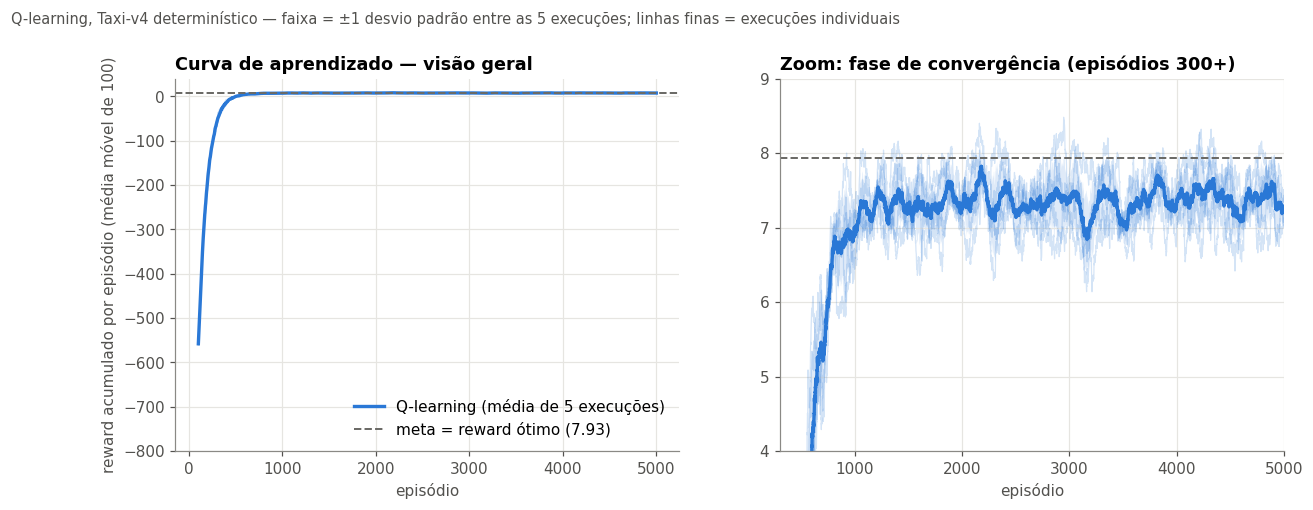

,episódios até a meta,reward médio 500 primeiros,reward médio 500 últimos,passos médios 500 últimos
1,740.00,-164.33,7.35,13.27
2,787.00,-162.61,7.23,13.37
3,759.00,-161.73,7.31,13.41
4,784.00,-164.30,7.36,13.40
5,772.00,-161.91,7.42,13.24
média,768.40,-162.97,7.33,13.34
desvio padrão,19.35,1.27,0.07,0.08


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
plot_learning(axes[0], [("Q-learning (média de 5 execuções)", Q_DET, C_Q)], opt=OPT_DET,
              opt_label=f"meta = reward ótimo ({OPT_DET:.2f})", ylim=(-800, 40))
axes[0].set_title("Curva de aprendizado — visão geral")
axes[0].set_ylabel("reward acumulado por episódio (média móvel de 100)")
axes[0].legend(loc="lower right")
plot_learning(axes[1], [("Q-learning", Q_DET, C_Q)], opt=OPT_DET, opt_label=f"meta = {OPT_DET:.2f}", xlim=(300, HP.n_episodes), ylim=(4, 9))
axes[1].set_title("Zoom: fase de convergência (episódios 300+)")
fig.suptitle("Q-learning, Taxi-v4 determinístico — faixa = ±1 desvio padrão entre as 5 execuções; linhas finas = execuções individuais",
             x=0.01, ha="left", fontsize=9.5, color="#52514e", y=1.02)
savefig(fig, "01_qlearning_det_curva"); plt.show()
display(with_summary(learning_metrics(Q_DET, OPT_DET)))

**Leitura da curva (Q-learning, determinístico).**

* **Início:** nos primeiros 500 episódios o reward médio é ≈ −163 por episódio. Com ε ≈ 1 o agente age quase aleatoriamente: o episódio estoura o limite de 200 passos (−200) e ainda acumula penalidades de −10 por pegar/deixar em local errado.
* **Aprendizado:** a curva sobe rapidamente e as 5 execuções entram na faixa "meta − 1.5" (média móvel ≥ 6.43) entre os episódios 740 e 787 (**768 ± 19**): o resultado é muito consistente entre seeds, o que mostra que a escolha de hiperparâmetros é robusta.
* **Meta:** o reward ótimo (calculado exatamente) é **7.93**. Nos últimos 500 episódios o reward de treino fica em **7.33 ± 0.07**, ~0.6 abaixo da meta. Isso **não** significa que a política é ruim: o reward de treino inclui os 1% de ações aleatórias que ainda restam (ε = 0.01); a política **gulosa** final obtém 7.90 em 5000 execuções (ótimo: 7.95, seção 4.3).

### 2.3 Item 2 — execução da política aprendida (100 execuções por agente)
Agora usamos a Q-table **sem exploração e sem aprender**: em cada estado o agente escolhe $\arg\max_a Q(s,a)$. Cada um dos 5 agentes executa a tarefa **100 vezes**
e registramos os **timesteps** até entregar o passageiro. Como referência, a **política ótima** (value iteration) executa nos **mesmos** 100 estados iniciais.

In [13]:
EV_Q_DET = eval_agents(Q_DET, rainy=False)
EV_OPT_DET = eval_agents([{"Q": Qopt_det}] * 5, rainy=False)      # política ótima exata, mesmos estados iniciais

print("Q-LEARNING treinado no determinístico, executado no determinístico (100 execuções por agente)")
display(eval_table(EV_Q_DET))
print("Referência: política ótima exata, mesmos 100 estados iniciais por execução")
display(eval_table(EV_OPT_DET).tail(1))

Q-LEARNING treinado no determinístico, executado no determinístico (100 execuções por agente)


,timesteps médio,desvio padrão,mín,máx,sucesso (%),reward médio
execução,,,,,,
1,12.84,2.76,6,18,100.00,8.16
2,13.05,2.65,6,18,100.00,7.95
3,13.18,2.73,6,18,100.00,7.82
4,13.34,2.45,6,18,100.00,7.66
5,13.62,2.66,7,18,100.00,7.38
todas (n=500),13.21,2.65,6,18,100.00,7.79


Referência: política ótima exata, mesmos 100 estados iniciais por execução


,timesteps médio,desvio padrão,mín,máx,sucesso (%),reward médio
execução,,,,,,
todas (n=500),13.16,2.67,6,18,100.00,7.84


In [14]:
# uma execução passo a passo (agente 1, 1º episódio de avaliação) para "enxergar" a política aprendida
def replay(Q, rainy, seed):
    env = make_env(rainy, render_mode="ansi"); greedy = Q.argmax(1)
    s, _ = env.reset(seed=seed); print(env.render()); acoes, tot, done = [], 0, False
    while not done:
        a = int(greedy[s]); s, r, term, trunc, _ = env.step(a); acoes.append(ACTION_NAMES[a]); tot += r; done = term or trunc
    print(env.render()); print(f"{len(acoes)} timesteps, reward {tot:.0f}:", " → ".join(acoes))
replay(Q_DET[0]["Q"], False, EVAL_SEED)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+


+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)

14 timesteps, reward 7: Leste → Sul → Leste → Leste → Norte → Norte → Leste → Pegar → Sul → Oeste → Sul → Sul → Sul → Deixar


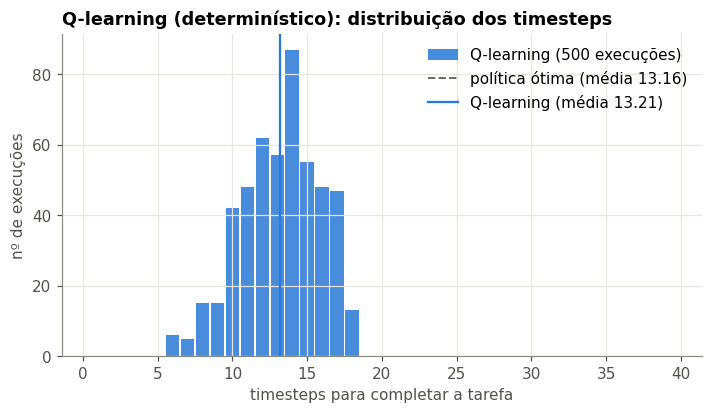

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bins = np.arange(0.5, 40.5, 1)
ax.hist(pooled(EV_Q_DET), bins=bins, color=C_Q, alpha=0.85, label="Q-learning (500 execuções)", rwidth=0.9)
ax.axvline(pooled(EV_OPT_DET).mean(), color=C_OPT, ls="--", lw=1.3, label=f"política ótima (média {pooled(EV_OPT_DET).mean():.2f})")
ax.axvline(pooled(EV_Q_DET).mean(), color=C_Q, lw=1.5, label=f"Q-learning (média {pooled(EV_Q_DET).mean():.2f})")
ax.set_xlabel("timesteps para completar a tarefa"); ax.set_ylabel("nº de execuções")
ax.set_title("Q-learning (determinístico): distribuição dos timesteps"); ax.legend()
savefig(fig, "02_qlearning_det_timesteps"); plt.show()

**Leitura (item 2, Q-learning).** Cada um dos 5 agentes completou a tarefa em **100%** das 100 execuções. Média geral: **13.21 ± 2.65 timesteps** (n = 500; mínimo 6, máximo 18; médias por agente entre 12.84 e 13.62).

* A política ótima, nos **mesmos** estados iniciais, obtém 13.16 ± 2.67: o Q-learning está a ~0.05 passo (0.4%) do ótimo. Na avaliação ampliada (1000 execuções por agente, seção 4.3) a diferença é 13.10 contra 13.05.
* As diferenças entre os agentes (12.84 a 13.62) são **ruído amostral**: com desvio ≈ 2.65 e 100 execuções, a incerteza de cada média é ≈ ±0.27.
* O desvio padrão (≈ 2.65) **não** indica inconsistência do agente: ele vem da variedade dos estados iniciais (táxi, passageiro e destino em posições diferentes exigem 6 a 18 passos). A própria política ótima tem o mesmo desvio (2.67).
* Na execução passo a passo acima, o agente 1 faz 14 passos: 7 movimentos até o passageiro, 1 "Pegar", 5 movimentos até o destino e 1 "Deixar".

## 3. SARSA no ambiente determinístico (mesmas análises, mesmos hiperparâmetros)

5 treinos de SARSA em 7s


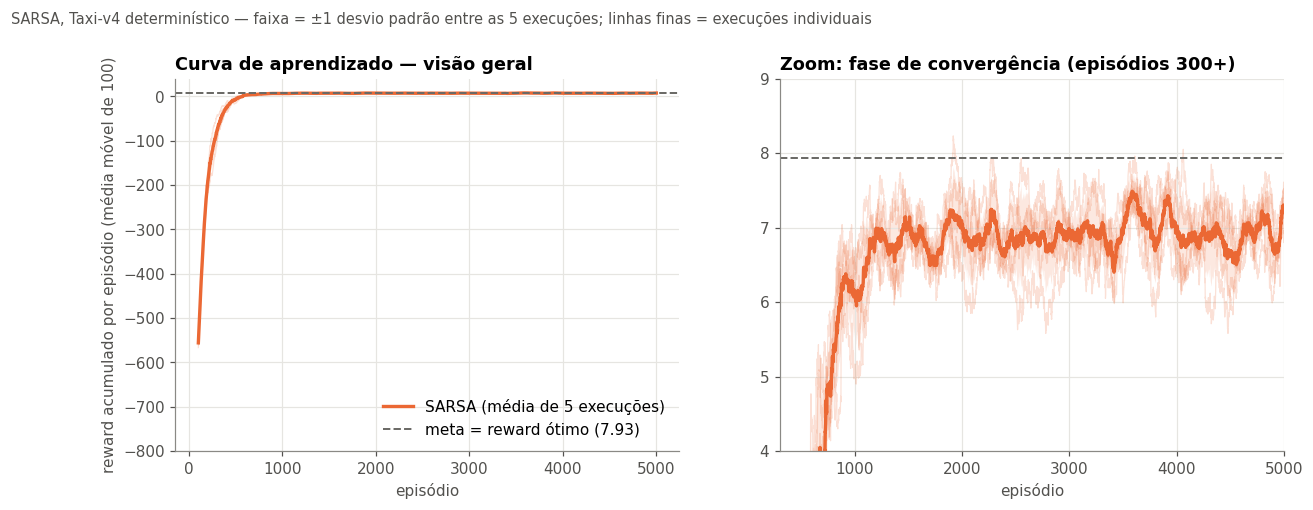

,episódios até a meta,reward médio 500 primeiros,reward médio 500 últimos,passos médios 500 últimos
1,824.00,-170.36,7.11,13.64
2,828.00,-179.39,6.96,13.61
3,852.00,-159.92,6.78,14.02
4,861.00,-172.87,6.89,13.82
5,991.00,-177.92,7.14,13.51
média,871.20,-172.09,6.98,13.72
desvio padrão,68.77,7.73,0.15,0.20


In [16]:
t0 = time.time()
S_DET = run_many("sarsa", HP, SEEDS, rainy=False)
save_runs("train_sarsa_det", S_DET)
print(f"5 treinos de SARSA em {time.time()-t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
plot_learning(axes[0], [("SARSA (média de 5 execuções)", S_DET, C_S)], opt=OPT_DET, opt_label=f"meta = reward ótimo ({OPT_DET:.2f})", ylim=(-800, 40))
axes[0].set_title("Curva de aprendizado — visão geral"); axes[0].set_ylabel("reward acumulado por episódio (média móvel de 100)"); axes[0].legend(loc="lower right")
plot_learning(axes[1], [("SARSA", S_DET, C_S)], opt=OPT_DET, opt_label=f"meta = {OPT_DET:.2f}", xlim=(300, HP.n_episodes), ylim=(4, 9))
axes[1].set_title("Zoom: fase de convergência (episódios 300+)")
fig.suptitle("SARSA, Taxi-v4 determinístico — faixa = ±1 desvio padrão entre as 5 execuções; linhas finas = execuções individuais",
             x=0.01, ha="left", fontsize=9.5, color="#52514e", y=1.02)
savefig(fig, "03_sarsa_det_curva"); plt.show()
display(with_summary(learning_metrics(S_DET, OPT_DET)))

In [17]:
EV_S_DET = eval_agents(S_DET, rainy=False)
print("SARSA treinado no determinístico, executado no determinístico (100 execuções por agente)")
display(eval_table(EV_S_DET))

SARSA treinado no determinístico, executado no determinístico (100 execuções por agente)


,timesteps médio,desvio padrão,mín,máx,sucesso (%),reward médio
execução,,,,,,
1,13.24,2.96,6,20,100.00,7.76
2,13.41,2.80,6,18,100.00,7.59
3,13.78,2.91,6,20,100.00,7.22
4,13.50,2.83,6,20,100.00,7.50
5,13.90,2.62,7,18,100.00,7.10
todas (n=500),13.57,2.82,6,20,100.00,7.43


**Leitura (SARSA).** Também completou a tarefa em **100%** das execuções: **13.57 ± 2.82 timesteps** (n = 500; mín. 6, máx. 20; médias por agente entre 13.24 e 13.90).
Aprendeu mais devagar que o Q-learning (871 ± 69 episódios até a meta, contra 768 ± 19) e a política final é ligeiramente mais longa (+0.36 passo sobre o Q-learning nos mesmos estados iniciais). A comparação formal está na seção 4.

## 4. Q-learning vs SARSA (item 3)

### 4.1 Curvas de aprendizado dos dois agentes em um único gráfico

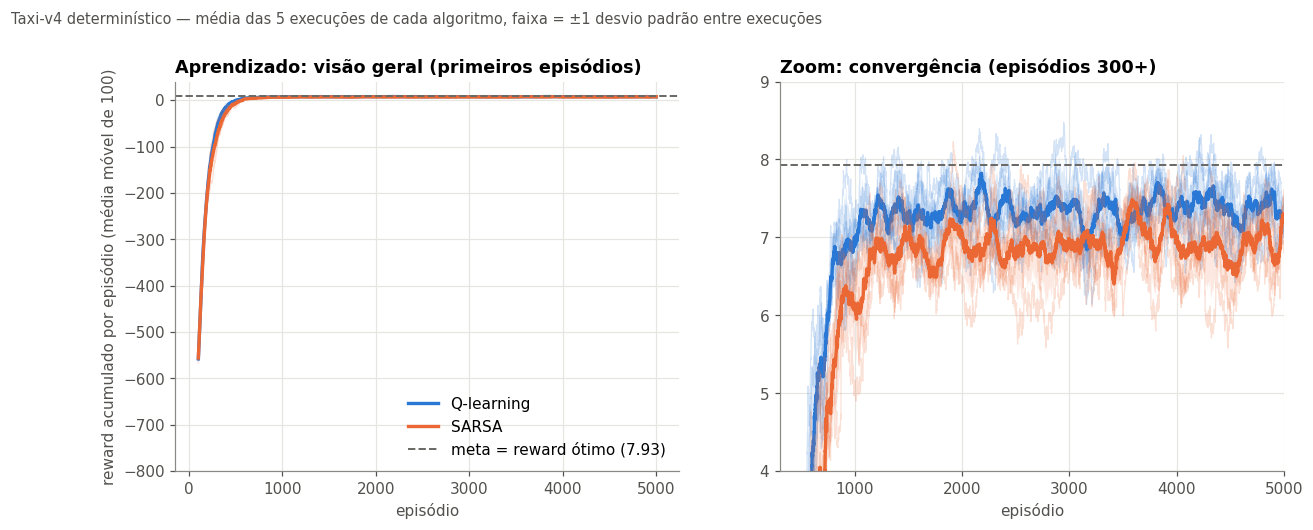

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
groups = [("Q-learning", Q_DET, C_Q), ("SARSA", S_DET, C_S)]
plot_learning(axes[0], groups, opt=OPT_DET, opt_label=f"meta = reward ótimo ({OPT_DET:.2f})", ylim=(-800, 40))
axes[0].set_title("Aprendizado: visão geral (primeiros episódios)"); axes[0].set_ylabel("reward acumulado por episódio (média móvel de 100)")
axes[0].legend(loc="lower right")
plot_learning(axes[1], groups, opt=OPT_DET, opt_label=f"meta = {OPT_DET:.2f}", xlim=(300, HP.n_episodes), ylim=(4, 9))
axes[1].set_title("Zoom: convergência (episódios 300+)")
fig.suptitle("Taxi-v4 determinístico — média das 5 execuções de cada algoritmo, faixa = ±1 desvio padrão entre execuções",
             x=0.01, ha="left", fontsize=9.5, color="#52514e", y=1.02)
savefig(fig, "04_q_vs_sarsa_det_curvas"); plt.show()

### 4.2 Eficiência no aprendizado

In [19]:
LM_Q, LM_S = learning_metrics(Q_DET, OPT_DET), learning_metrics(S_DET, OPT_DET)
comp = pd.DataFrame({
    "Q-learning": [f"{LM_Q[c].mean():.1f} ± {LM_Q[c].std():.1f}" for c in LM_Q.columns],
    "SARSA":      [f"{LM_S[c].mean():.1f} ± {LM_S[c].std():.1f}" for c in LM_S.columns],
    "p-valor (Welch, n=5 vs 5)": [f"{stats.ttest_ind(LM_Q[c].dropna(), LM_S[c].dropna(), equal_var=False).pvalue:.3f}" for c in LM_Q.columns]},
    index=LM_Q.columns)
print("média ± desvio padrão entre as 5 execuções de treino")
display(comp)
print("execuções que nunca atingiram a meta:", int(LM_Q.iloc[:, 0].isna().sum()), "(Q-learning),", int(LM_S.iloc[:, 0].isna().sum()), "(SARSA)")

média ± desvio padrão entre as 5 execuções de treino


,Q-learning,SARSA,"p-valor (Welch, n=5 vs 5)"
episódios até a meta,768.4 ± 19.3,871.2 ± 68.8,0.026
reward médio 500 primeiros,-163.0 ± 1.3,-172.1 ± 7.7,0.057
reward médio 500 últimos,7.3 ± 0.1,7.0 ± 0.2,0.004
passos médios 500 últimos,13.3 ± 0.1,13.7 ± 0.2,0.010


execuções que nunca atingiram a meta: 0 (Q-learning), 0 (SARSA)


### 4.3 Desempenho final (política gulosa)

In [20]:
# mesma avaliação de 100 execuções por agente (n=500 por algoritmo) + avaliação ampliada de 1000 execuções por agente (n=5000) para reduzir ruído amostral
EV_Q_DET_BIG = eval_agents(Q_DET, False, n=1000, seed_base=900_000)
EV_S_DET_BIG = eval_agents(S_DET, False, n=1000, seed_base=900_000)
EV_OPT_DET_BIG = eval_agents([{"Q": Qopt_det}] * 5, False, n=1000, seed_base=900_000)

def linha(nome, evs):
    st, su, rw = pooled(evs), pooled(evs, "success"), pooled(evs, "rewards")
    medias = [e["steps"].mean() for e in evs]
    return {"agente": nome, "timesteps médio": st.mean(), "desvio padrão": st.std(ddof=1), "mediana": np.median(st),
            "média por agente ± dp (5 agentes)": f"{np.mean(medias):.2f} ± {np.std(medias, ddof=1):.2f}",
            "sucesso (%)": 100 * su.mean(), "reward médio": rw.mean()}

print("Avaliação do enunciado: 100 execuções por agente (500 por algoritmo)")
display(pd.DataFrame([linha("Q-learning", EV_Q_DET), linha("SARSA", EV_S_DET), linha("Ótimo (referência)", EV_OPT_DET)]).set_index("agente"))
print("Avaliação ampliada: 1000 execuções por agente (5000 por algoritmo)")
display(pd.DataFrame([linha("Q-learning", EV_Q_DET_BIG), linha("SARSA", EV_S_DET_BIG), linha("Ótimo (referência)", EV_OPT_DET_BIG)]).set_index("agente"))

mq = [e["steps"].mean() for e in EV_Q_DET_BIG]; ms = [e["steps"].mean() for e in EV_S_DET_BIG]
print(f"Teste de Welch nas médias por agente (n=5 vs 5): p = {stats.ttest_ind(mq, ms, equal_var=False).pvalue:.3f}")

Avaliação do enunciado: 100 execuções por agente (500 por algoritmo)


,timesteps médio,desvio padrão,mediana,média por agente ± dp (5 agentes),sucesso (%),reward médio
agente,,,,,,
Q-learning,13.21,2.65,13.50,13.21 ± 0.30,100.00,7.79
SARSA,13.57,2.82,14.00,13.57 ± 0.27,100.00,7.43
Ótimo (referência),13.16,2.67,13.00,13.16 ± 0.29,100.00,7.84


Avaliação ampliada: 1000 execuções por agente (5000 por algoritmo)


,timesteps médio,desvio padrão,mediana,média por agente ± dp (5 agentes),sucesso (%),reward médio
agente,,,,,,
Q-learning,13.10,2.60,13.00,13.10 ± 0.09,100.00,7.90
SARSA,13.51,2.79,14.00,13.51 ± 0.13,100.00,7.49
Ótimo (referência),13.05,2.62,13.00,13.05 ± 0.05,100.00,7.95


Teste de Welch nas médias por agente (n=5 vs 5): p = 0.001


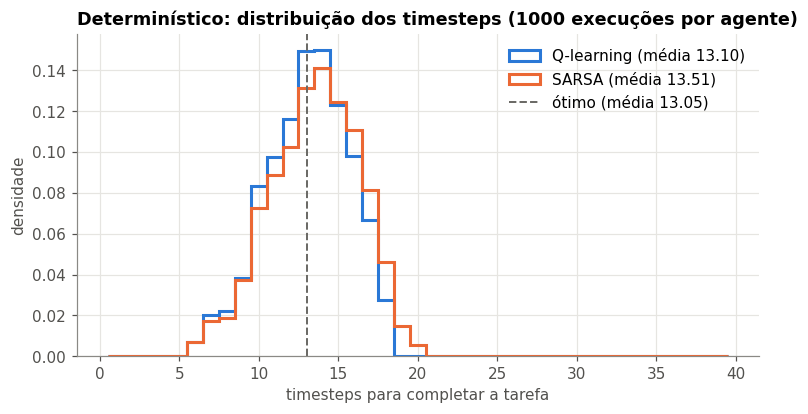

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.arange(0.5, 40.5, 1)
for label, ev, c in [("Q-learning", EV_Q_DET_BIG, C_Q), ("SARSA", EV_S_DET_BIG, C_S)]:
    ax.hist(pooled(ev), bins=bins, histtype="step", lw=2, color=c, label=f"{label} (média {pooled(ev).mean():.2f})", density=True)
ax.axvline(pooled(EV_OPT_DET_BIG).mean(), color=C_OPT, ls="--", lw=1.3, label=f"ótimo (média {pooled(EV_OPT_DET_BIG).mean():.2f})")
ax.set_xlabel("timesteps para completar a tarefa"); ax.set_ylabel("densidade")
ax.set_title("Determinístico: distribuição dos timesteps (1000 execuções por agente)"); ax.legend()
savefig(fig, "05_q_vs_sarsa_det_timesteps"); plt.show()

**Item 3 — diferenças entre Q-learning e SARSA (determinístico)**

| | Q-learning | SARSA | Diferença |
|---|---|---|---|
| Episódios até a meta | 768 ± 19 | 871 ± 69 | SARSA ~13% mais lento (Welch p ≈ 0.03) |
| Reward médio nos 500 primeiros episódios | −163.0 ± 1.3 | −172.1 ± 7.7 | tendência a favor do Q-learning, **não** significativa (p ≈ 0.06) |
| Reward de treino nos 500 últimos | 7.33 ± 0.07 | 6.98 ± 0.15 | Q-learning maior (p < 0.01) |
| Timesteps da política final (1000 exec./agente) | 13.10 | 13.51 | SARSA +0.41 passo (+3%; p ≈ 0.001) |
| Sucesso | 100% | 100% | igual |
| Ótimo (referência) | 13.05 | | Q-learning está a 0.05 do ótimo; SARSA a 0.46 |

**Eficiência no aprendizado.** Os dois aprendem em cerca de 800–900 episódios e a curva dos dois é parecida (gráfico acima), mas o Q-learning é um pouco **mais rápido e muito mais regular** entre execuções (desvio de 19 contra 69 episódios).
No reward de treino em regime, o Q-learning fica ~0.35 acima.

**Desempenho final.** Ambos resolvem 100% das tarefas; o Q-learning é praticamente ótimo (13.10 contra 13.05) e o SARSA gasta ~3% mais passos. A diferença é pequena em valores absolutos, mas **consistente**: significativa no teste de Welch sobre as médias dos 5 agentes (p ≈ 0.001), e também na avaliação de 100 execuções (13.21 contra 13.57).

**Por que isso acontece?** A diferença está só no alvo da atualização.
O Q-learning usa $\max_{a'}Q(s',a')$: aprende o valor da política **ótima**, independentemente de como explora. O SARSA usa $Q(s',a')$ com a ação que a política ε-greedy realmente escolhe, então aprende o valor da política **com exploração**: suas estimativas embutem o custo das ações aleatórias (por exemplo, um "pegar/deixar" errado, −10) e ficam mais pessimistas e mais ruidosas, e isso desloca ligeiramente a política gulosa em alguns estados.
A vantagem clássica do SARSA (aprender trajetórias mais **seguras** perto de perigos, como no *Cliff Walking*) quase não tem utilidade aqui: o Taxi não tem penhasco, e a penalidade por erro é pequena e local. Por isso o Q-learning leva vantagem.

**Ressalvas.** (i) São só 5 execuções por algoritmo, então o teste tem pouco poder; (ii) o resultado depende dos hiperparâmetros: na busca da seção 1, com α = 0.1 o SARSA alcança o mesmo desempenho final do Q-learning (13.27 passos nos dois), só que mais devagar — ou seja, o SARSA é mais sensível ao α do que o Q-learning; (iii) como o enunciado pede os **mesmos** hiperparâmetros, a comparação reflete uma configuração escolhida olhando o Q-learning.

## 5. Ambiente não determinístico (itens 4 e 5)

### 5.1 A Q-table aprendida no ambiente determinístico continua eficaz no ambiente chuvoso? (item 4)
Pegamos **as mesmas Q-tables** treinadas no ambiente determinístico (seção 2 e 3) e as executamos no ambiente com `is_rainy=True, rainy_probability=0.6`, 100 execuções por agente, **sem retreinar**.
Como referência incluímos (i) a política ótima do ambiente chuvoso e (ii) a política ótima do ambiente **determinístico** executada na chuva
(isto separa "o que se perde por a chuva ser mais difícil" de "o que se perde por a política não ter sido adaptada à chuva").

In [22]:
EV_Q_T  = eval_agents(Q_DET, rainy=True)           # Q-tables do determinístico, executadas no chuvoso
EV_S_T  = eval_agents(S_DET, rainy=True)
EV_OPT_RAIN   = eval_agents([{"Q": Qopt_rain}] * 5, rainy=True)    # política ótima do chuvoso
EV_OPTDET_RAIN = eval_agents([{"Q": Qopt_det}] * 5, rainy=True)    # política ótima do determinístico executada na chuva

print("Q-LEARNING (treinado no determinístico) executado no CHUVOSO — 100 execuções por agente")
display(eval_table(EV_Q_T))
print("SARSA (treinado no determinístico) executado no CHUVOSO — 100 execuções por agente")
display(eval_table(EV_S_T))

Q-LEARNING (treinado no determinístico) executado no CHUVOSO — 100 execuções por agente


,timesteps médio,desvio padrão,mín,máx,sucesso (%),reward médio
execução,,,,,,
1,31.93,31.40,7,200,97.00,-11.56
2,46.40,57.77,8,200,88.00,-27.92
3,42.97,53.47,7,200,90.00,-24.07
4,27.35,19.98,9,200,99.00,-6.56
5,38.40,45.98,10,200,93.00,-18.87
todas (n=500),37.41,44.41,7,200,93.40,-17.80


SARSA (treinado no determinístico) executado no CHUVOSO — 100 execuções por agente


,timesteps médio,desvio padrão,mín,máx,sucesso (%),reward médio
execução,,,,,,
1,29.51,20.40,7,200,99.00,-8.72
2,31.98,27.00,8,200,98.00,-11.40
3,29.42,20.34,7,200,99.00,-8.63
4,37.51,42.72,8,200,94.00,-17.77
5,33.47,35.80,9,200,96.00,-13.31
todas (n=500),32.38,30.57,7,200,97.20,-11.97


In [23]:
rows = [linha("Q-learning (det → chuvoso)", EV_Q_T), linha("SARSA (det → chuvoso)", EV_S_T),
        linha("Política ótima do determinístico, na chuva", EV_OPTDET_RAIN), linha("Política ótima do chuvoso", EV_OPT_RAIN)]
tab_t = pd.DataFrame(rows).set_index("agente")
tab_t["trunc. em 200 passos (%)"] = [100 * (pooled(e) == 200).mean() for e in (EV_Q_T, EV_S_T, EV_OPTDET_RAIN, EV_OPT_RAIN)]
display(tab_t)

# comparação com o desempenho no ambiente determinístico (mesmos agentes, mesmos estados iniciais)
cmp4 = pd.DataFrame({
    "timesteps médio — determinístico": [pooled(EV_Q_DET).mean(), pooled(EV_S_DET).mean()],
    "desvio padrão — determinístico":   [pooled(EV_Q_DET).std(ddof=1), pooled(EV_S_DET).std(ddof=1)],
    "timesteps médio — chuvoso":        [pooled(EV_Q_T).mean(), pooled(EV_S_T).mean()],
    "desvio padrão — chuvoso":          [pooled(EV_Q_T).std(ddof=1), pooled(EV_S_T).std(ddof=1)]}, index=["Q-learning", "SARSA"])
cmp4["aumento (×)"] = cmp4["timesteps médio — chuvoso"] / cmp4["timesteps médio — determinístico"]
display(cmp4)

,timesteps médio,desvio padrão,mediana,média por agente ± dp (5 agentes),sucesso (%),reward médio,trunc. em 200 passos (%)
agente,,,,,,,
Q-learning (det → chuvoso),37.41,44.41,25.00,37.41 ± 7.81,93.40,-17.80,6.60
SARSA (det → chuvoso),32.38,30.57,26.00,32.38 ± 3.34,97.20,-11.97,2.80
"Política ótima do determinístico, na chuva",25.08,9.73,24.00,25.08 ± 0.71,100.00,-4.08,0.00
Política ótima do chuvoso,25.11,9.69,24.00,25.11 ± 0.82,100.00,-4.11,0.00


,timesteps médio — determinístico,desvio padrão — determinístico,timesteps médio — chuvoso,desvio padrão — chuvoso,aumento (×)
Q-learning,13.21,2.65,37.41,44.41,2.83
SARSA,13.57,2.82,32.38,30.57,2.39


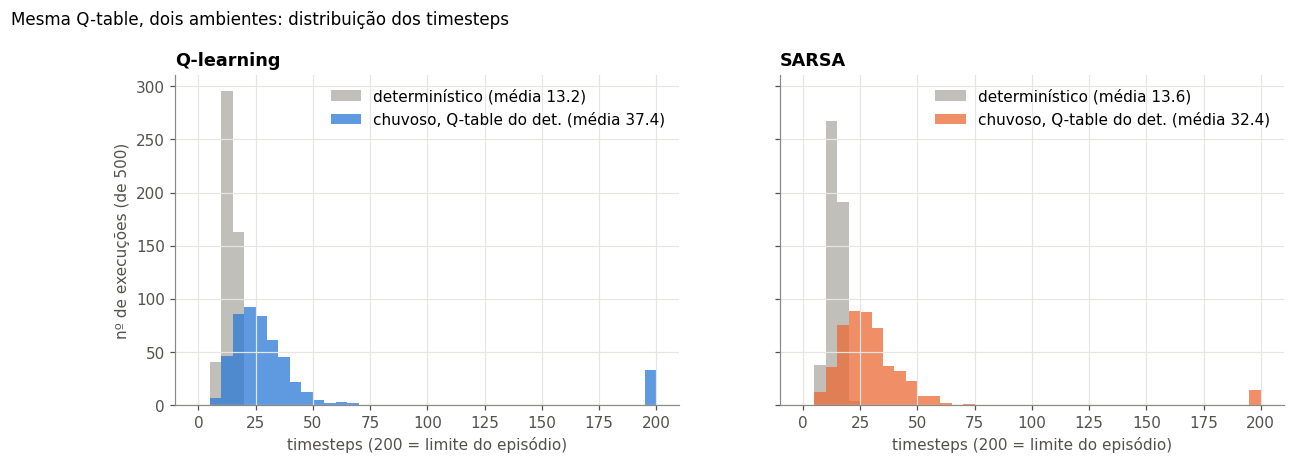

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), sharey=True)
bins = np.arange(0, 205, 5)
for ax, (nome, e_det, e_t, c) in zip(axes, [("Q-learning", EV_Q_DET, EV_Q_T, C_Q), ("SARSA", EV_S_DET, EV_S_T, C_S)]):
    ax.hist(pooled(e_det), bins=bins, color="#b9b8b2", alpha=0.9, label=f"determinístico (média {pooled(e_det).mean():.1f})")
    ax.hist(pooled(e_t), bins=bins, color=c, alpha=0.75, label=f"chuvoso, Q-table do det. (média {pooled(e_t).mean():.1f})")
    ax.set_title(nome); ax.set_xlabel("timesteps (200 = limite do episódio)"); ax.legend()
axes[0].set_ylabel("nº de execuções (de 500)")
fig.suptitle("Mesma Q-table, dois ambientes: distribuição dos timesteps", x=0.01, ha="left", fontsize=11, y=1.03)
savefig(fig, "06_transferencia_det_para_chuva"); plt.show()

**Diagnóstico das falhas.** Algumas execuções chegam ao limite de 200 passos (barra isolada em 200). Por quê? Para cada falha verificamos o estado em que o agente terminou
e se a ação gulosa naquele estado é **sem efeito** (bater na parede ou pegar/deixar em local ilegal: o táxi permanece no mesmo estado, então ele repete a ação para sempre).
Também verificamos se esse estado **faz parte da rota** que o agente percorre no ambiente determinístico (rodando a política gulosa a partir dos 300 estados iniciais possíveis).

In [25]:
def diagnostico_falhas(results, n=100):
    env_r, env_d = make_env(True), make_env(False)
    P = env_r.unwrapped.P
    iniciais = np.flatnonzero(env_d.unwrapped.initial_state_distrib)          # 300 estados iniciais possíveis
    falhas = sem_efeito = fora_rota = 0
    for k, r in enumerate(results):
        g = r["Q"].argmax(1)
        rota = set()                                                          # estados visitados na política gulosa, ambiente determinístico
        for s0 in iniciais:
            env_d.reset(seed=0); env_d.unwrapped.s = int(s0); s, done = int(s0), False
            while not done:
                rota.add(s); s, _, term, trunc, _ = env_d.step(int(g[s])); done = term or trunc
        for i in range(n):                                                    # mesmas 100 execuções da tabela acima
            s, _ = env_r.reset(seed=EVAL_SEED + 1000 * k + i); done = False
            while not done:
                s, _, term, trunc, _ = env_r.step(int(g[s])); done = term or trunc
            if trunc and not term:
                falhas += 1
                sem_efeito += all(s2 == s for _, s2, _, _ in P[s][int(g[s])])
                fora_rota += s not in rota
    return falhas, sem_efeito, fora_rota

linhas = []
for nome, res in [("Q-learning (det → chuvoso)", Q_DET), ("SARSA (det → chuvoso)", S_DET)]:
    f, se, fr = diagnostico_falhas(res)
    linhas.append({"agente": nome, "falhas (de 500)": f, "ação gulosa sem efeito no estado final": f"{se} ({100*se/max(f,1):.0f}%)",
                   "estado final fora da rota do determinístico": f"{fr} ({100*fr/max(f,1):.0f}%)"})
display(pd.DataFrame(linhas).set_index("agente"))

,falhas (de 500),ação gulosa sem efeito no estado final,estado final fora da rota do determinístico
agente,,,
Q-learning (det → chuvoso),33,33 (100%),33 (100%)
SARSA (det → chuvoso),14,14 (100%),14 (100%)


**Item 4 — a Q-table do determinístico funciona no ambiente chuvoso?**

Resultado (100 execuções por agente, n = 500, sem retreinar):

| Agente (treinado no determinístico) | Determinístico | Chuvoso (média ± dp) | Mediana no chuvoso | Sucesso no chuvoso |
|---|---|---|---|---|
| Q-learning | 13.21 ± 2.65 | **37.41 ± 44.41** (×2.8) | 25 | 93.4% |
| SARSA | 13.57 ± 2.82 | **32.38 ± 30.57** (×2.4) | 26 | 97.2% |
| Ótimo do chuvoso (referência) | — | 25.11 ± 9.69 | 24 | 100% |

**A resposta é "parcialmente".** Três efeitos se misturam:

1. **A chuva torna a tarefa intrinsecamente mais longa.** Mesmo a política **ótima** precisa de ≈ 25 passos no chuvoso (contra 13 no determinístico), porque cada movimento só sai como pedido em 60% das vezes. Esse acréscimo é inevitável (e a política ótima do determinístico, executada na chuva, faz 25.08 passos, praticamente igual à ótima do chuvoso: a "rota" ideal é a mesma).
2. **Na maioria dos episódios o agente continua bom:** a **mediana** (25 e 26 passos) é essencialmente a do ótimo (24). A Q-table transferida funciona como política.
3. **Mas não é robusta:** 6.6% (Q-learning) e 2.8% (SARSA) das execuções **estouram os 200 passos**, e essas poucas falhas inflam a média (37.4 e 32.4) e o desvio padrão (44 e 31, contra 9.7 do ótimo). Em 1000 execuções por agente: 5.4% e 3.3% de falhas.

**Por que falham?** O diagnóstico acima mostra que **100% das falhas** (33 de 33 no Q-learning, 14 de 14 no SARSA) terminam num estado que **está fora da rota** que o agente percorre no determinístico e onde a ação gulosa **não tem efeito** (por exemplo, bater na parede): o táxi fica preso em loop até o limite de passos.
No ambiente determinístico o agente segue sempre a mesma rota e quase nunca visita os estados fora dela, então as estimativas de Q nesses estados ficam **desatualizadas**: vêm das primeiras tentativas (quase aleatórias) e nunca foram corrigidas. Um exemplo concreto, conferido na Q-table do agente 2 de Q-learning: no canto inferior direito, com o passageiro dentro do táxi e destino em Y (estado 498), as quatro direções valem ≈ −3.6 na Q-table, enquanto o valor ótimo de Norte e Oeste é ≈ +10. Como as estimativas ficam praticamente empatadas, a ação gulosa pode ser uma que bate na parede, e o agente nunca mais sai dali. Na chuva, o deslizamento lateral joga o táxi nesses estados, e a política aprendida não sabe sair deles.
Ou seja, a **aleatoriedade do ambiente expõe a parte da Q-table que o aprendizado determinístico nunca precisou refinar**.

**Q-learning × SARSA na transferência.** Na avaliação do enunciado o SARSA se saiu melhor (32.4 contra 37.4), mas na avaliação de 1000 execuções a diferença quase desaparece (33.1 contra 35.3, com variação entre agentes de 3 a 4 passos): **não há evidência de que um seja mais robusto que o outro**; a taxa de falhas depende de quais estados cada tabela deixou mal-estimados.

### 5.2 Treinando diretamente no ambiente chuvoso (item 5)
Treinamos agora Q-learning e SARSA **dentro** do ambiente `is_rainy=True, rainy_probability=0.6`, com os mesmos hiperparâmetros e as mesmas seeds.

10 treinos no ambiente chuvoso em 19s


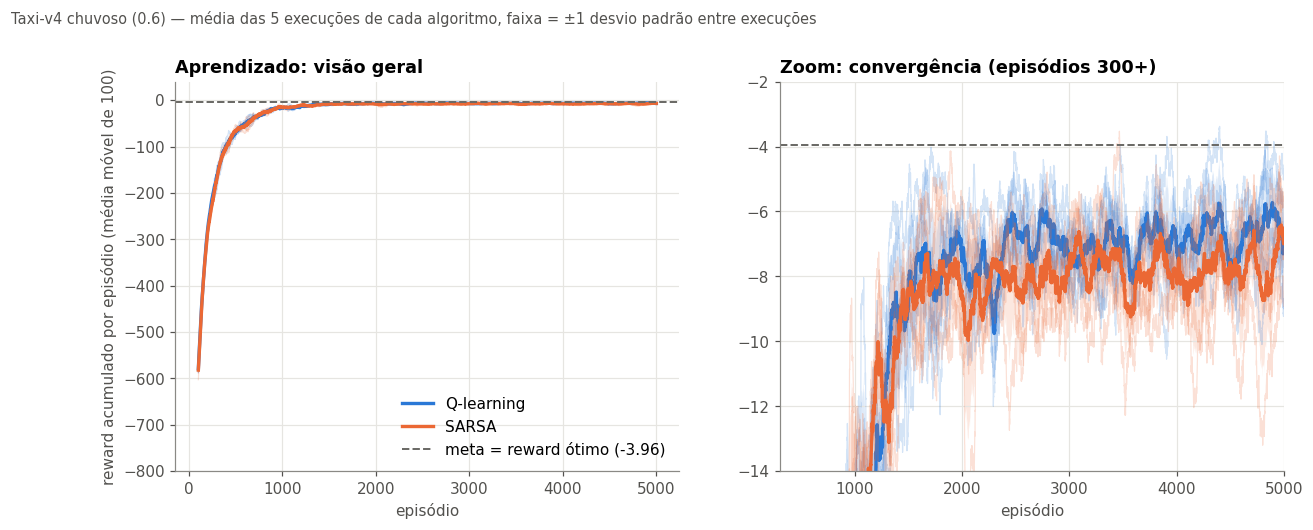

Q-learning (chuvoso)


,episódios até a meta,reward médio 500 primeiros,reward médio 500 últimos,passos médios 500 últimos
1,"1,644.00",-240.42,-6.08,26.15
2,"2,428.00",-229.27,-7.80,27.93
3,"2,066.00",-242.54,-7.01,27.08
4,"1,493.00",-237.35,-6.39,26.50
5,"2,751.00",-236.39,-6.00,26.24
média,"2,076.40",-237.20,-6.66,26.78
desvio padrão,525.87,5.06,0.75,0.74


SARSA (chuvoso)


,episódios até a meta,reward médio 500 primeiros,reward médio 500 últimos,passos médios 500 últimos
1,"2,452.00",-242.50,-6.93,27.10
2,NaN,-239.89,-10.45,30.59
3,"1,608.00",-239.53,-6.63,27.00
4,"1,661.00",-240.19,-8.04,28.01
5,"1,991.00",-240.17,-6.61,26.84
média,"1,928.00",-240.46,-7.73,27.91
desvio padrão,388.26,1.18,1.63,1.56


In [26]:
t0 = time.time()
Q_RAIN = run_many("qlearning", HP, SEEDS, rainy=True)
S_RAIN = run_many("sarsa", HP, SEEDS, rainy=True)
save_runs("train_qlearning_rainy", Q_RAIN); save_runs("train_sarsa_rainy", S_RAIN)
print(f"10 treinos no ambiente chuvoso em {time.time()-t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
groups = [("Q-learning", Q_RAIN, C_Q), ("SARSA", S_RAIN, C_S)]
plot_learning(axes[0], groups, opt=OPT_RAIN, opt_label=f"meta = reward ótimo ({OPT_RAIN:.2f})", ylim=(-800, 40))
axes[0].set_title("Aprendizado: visão geral"); axes[0].set_ylabel("reward acumulado por episódio (média móvel de 100)"); axes[0].legend(loc="lower right")
plot_learning(axes[1], groups, opt=OPT_RAIN, opt_label=f"meta = {OPT_RAIN:.2f}", xlim=(300, HP.n_episodes), ylim=(-14, -2))
axes[1].set_title("Zoom: convergência (episódios 300+)")
fig.suptitle("Taxi-v4 chuvoso (0.6) — média das 5 execuções de cada algoritmo, faixa = ±1 desvio padrão entre execuções",
             x=0.01, ha="left", fontsize=9.5, color="#52514e", y=1.02)
savefig(fig, "07_q_vs_sarsa_chuva_curvas"); plt.show()

LMQ_R, LMS_R = learning_metrics(Q_RAIN, OPT_RAIN), learning_metrics(S_RAIN, OPT_RAIN)
print("Q-learning (chuvoso)"); display(with_summary(LMQ_R))
print("SARSA (chuvoso)");      display(with_summary(LMS_R))

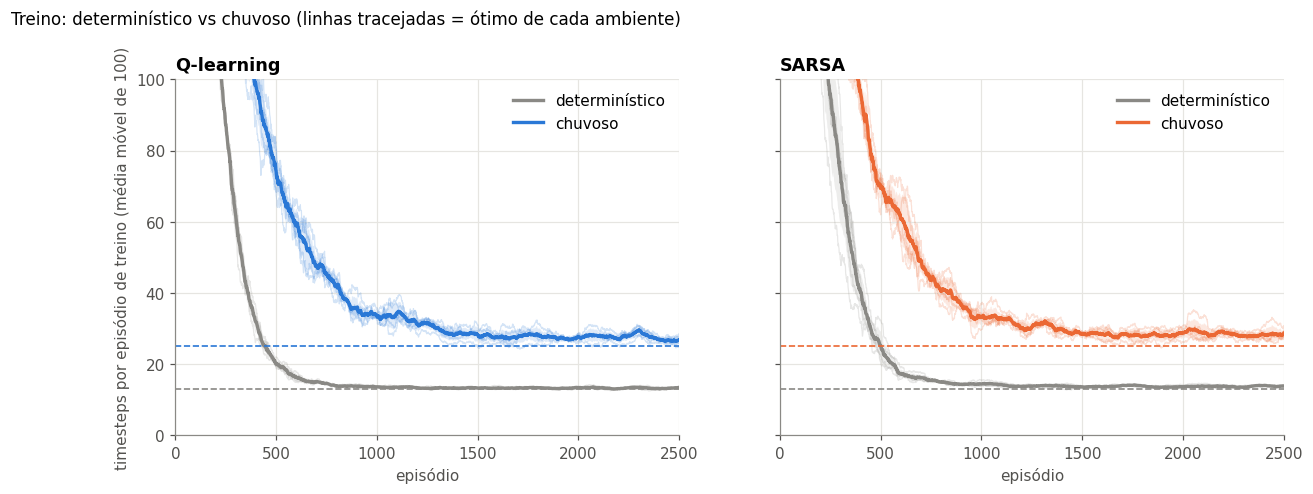

In [27]:
# Determinístico vs chuvoso, por algoritmo: passos por episódio durante o treino (comparável entre ambientes)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (nome, rd, rr, c) in zip(axes, [("Q-learning", Q_DET, Q_RAIN, C_Q), ("SARSA", S_DET, S_RAIN, C_S)]):
    plot_learning(ax, [("determinístico", rd, "#8a8985"), (f"chuvoso", rr, c)], key="steps", opt=None, xlim=(0, 2500), ylim=(0, 100))
    ax.axhline(21 - OPT_DET, color="#8a8985", ls="--", lw=1.1); ax.axhline(21 - OPT_RAIN, color=c, ls="--", lw=1.1)
    ax.set_title(nome); ax.legend(loc="upper right")
axes[0].set_ylabel("timesteps por episódio de treino (média móvel de 100)")
fig.suptitle("Treino: determinístico vs chuvoso (linhas tracejadas = ótimo de cada ambiente)", x=0.01, ha="left", fontsize=11, y=1.03)
savefig(fig, "08_det_vs_chuva_treino"); plt.show()

In [28]:
EV_Q_R = eval_agents(Q_RAIN, rainy=True)
EV_S_R = eval_agents(S_RAIN, rainy=True)
EV_Q_R_BIG = eval_agents(Q_RAIN, True, n=1000, seed_base=900_000)
EV_S_R_BIG = eval_agents(S_RAIN, True, n=1000, seed_base=900_000)
EV_Q_T_BIG = eval_agents(Q_DET, True, n=1000, seed_base=900_000)
EV_S_T_BIG = eval_agents(S_DET, True, n=1000, seed_base=900_000)
EV_OPT_RAIN_BIG = eval_agents([{"Q": Qopt_rain}] * 5, True, n=1000, seed_base=900_000)

print("Q-LEARNING treinado no CHUVOSO, executado no chuvoso — 100 execuções por agente"); display(eval_table(EV_Q_R))
print("SARSA treinado no CHUVOSO, executado no chuvoso — 100 execuções por agente");      display(eval_table(EV_S_R))

Q-LEARNING treinado no CHUVOSO, executado no chuvoso — 100 execuções por agente


,timesteps médio,desvio padrão,mín,máx,sucesso (%),reward médio
execução,,,,,,
1,26.47,9.59,7,53,100.00,-5.47
2,28.06,11.05,8,53,100.00,-7.06
3,27.51,11.65,7,59,100.00,-6.51
4,25.32,9.39,8,64,100.00,-4.32
5,26.03,10.70,9,69,100.00,-5.03
todas (n=500),26.68,10.52,7,69,100.00,-5.68


SARSA treinado no CHUVOSO, executado no chuvoso — 100 execuções por agente


,timesteps médio,desvio padrão,mín,máx,sucesso (%),reward médio
execução,,,,,,
1,27.33,10.12,7,56,100.00,-6.33
2,27.87,11.77,9,78,100.00,-6.87
3,26.87,10.08,7,60,100.00,-5.87
4,26.30,10.28,8,73,100.00,-5.30
5,27.42,10.95,9,61,100.00,-6.42
todas (n=500),27.16,10.63,7,78,100.00,-6.16


In [29]:
def tabela_condicoes(evs_dict):
    rows = []
    for nome, evs in evs_dict.items():
        d = linha(nome, evs); d["trunc. 200 passos (%)"] = 100 * (pooled(evs) == 200).mean(); rows.append(d)
    return pd.DataFrame(rows).set_index("agente")

print("Ambiente chuvoso — avaliação do enunciado (100 execuções por agente)")
display(tabela_condicoes({"Q-learning treinado no chuvoso": EV_Q_R, "SARSA treinado no chuvoso": EV_S_R,
                          "Q-learning treinado no det. (transferência)": EV_Q_T, "SARSA treinado no det. (transferência)": EV_S_T,
                          "Ótimo do chuvoso (referência)": EV_OPT_RAIN}))
print("Ambiente chuvoso — avaliação ampliada (1000 execuções por agente)")
display(tabela_condicoes({"Q-learning treinado no chuvoso": EV_Q_R_BIG, "SARSA treinado no chuvoso": EV_S_R_BIG,
                          "Q-learning treinado no det. (transferência)": EV_Q_T_BIG, "SARSA treinado no det. (transferência)": EV_S_T_BIG,
                          "Ótimo do chuvoso (referência)": EV_OPT_RAIN_BIG}))

mq = [e["steps"].mean() for e in EV_Q_R_BIG]; ms = [e["steps"].mean() for e in EV_S_R_BIG]
print(f"Q-learning vs SARSA treinados no chuvoso (médias por agente, Welch n=5 vs 5): p = {stats.ttest_ind(mq, ms, equal_var=False).pvalue:.3f}")
mt = [e["steps"].mean() for e in EV_Q_T_BIG]
print(f"Q-learning: treinado no chuvoso vs transferido do det. (Welch n=5 vs 5): p = {stats.ttest_ind(mq, mt, equal_var=False).pvalue:.4f}")
ms_t = [e["steps"].mean() for e in EV_S_T_BIG]
print(f"SARSA:      treinado no chuvoso vs transferido do det. (Welch n=5 vs 5): p = {stats.ttest_ind(ms, ms_t, equal_var=False).pvalue:.4f}")

Ambiente chuvoso — avaliação do enunciado (100 execuções por agente)


,timesteps médio,desvio padrão,mediana,média por agente ± dp (5 agentes),sucesso (%),reward médio,trunc. 200 passos (%)
agente,,,,,,,
Q-learning treinado no chuvoso,26.68,10.52,26.00,26.68 ± 1.11,100.00,-5.68,0.00
SARSA treinado no chuvoso,27.16,10.63,26.00,27.16 ± 0.60,100.00,-6.16,0.00
Q-learning treinado no det. (transferência),37.41,44.41,25.00,37.41 ± 7.81,93.40,-17.80,6.60
SARSA treinado no det. (transferência),32.38,30.57,26.00,32.38 ± 3.34,97.20,-11.97,2.80
Ótimo do chuvoso (referência),25.11,9.69,24.00,25.11 ± 0.82,100.00,-4.11,0.00


Ambiente chuvoso — avaliação ampliada (1000 execuções por agente)


,timesteps médio,desvio padrão,mediana,média por agente ± dp (5 agentes),sucesso (%),reward médio,trunc. 200 passos (%)
agente,,,,,,,
Q-learning treinado no chuvoso,26.30,9.97,25.00,26.30 ± 0.32,100.00,-5.30,0.00
SARSA treinado no chuvoso,27.33,10.55,26.00,27.33 ± 0.69,100.00,-6.33,0.00
Q-learning treinado no det. (transferência),35.31,40.57,25.00,35.31 ± 4.02,94.60,-15.44,5.40
SARSA treinado no det. (transferência),33.05,32.83,26.00,33.05 ± 3.14,96.66,-12.76,3.34
Ótimo do chuvoso (referência),24.74,9.23,23.00,24.74 ± 0.32,100.00,-3.74,0.00


Q-learning vs SARSA treinados no chuvoso (médias por agente, Welch n=5 vs 5): p = 0.026
Q-learning: treinado no chuvoso vs transferido do det. (Welch n=5 vs 5): p = 0.0072
SARSA:      treinado no chuvoso vs transferido do det. (Welch n=5 vs 5): p = 0.0136


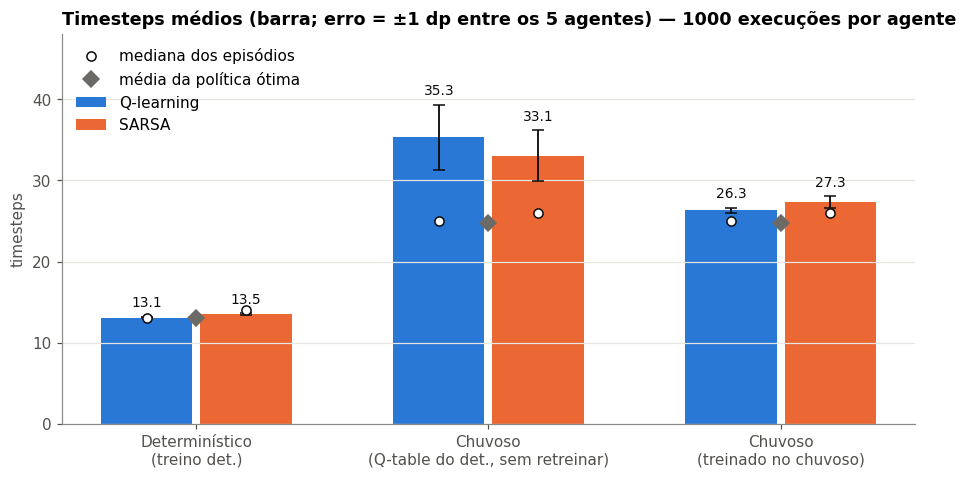

In [30]:
# Resumo visual: média de timesteps (± desvio padrão dos episódios) por condição e algoritmo; losango cinza = ótimo daquele ambiente
conds = [("Determinístico\n(treino det.)", EV_Q_DET_BIG, EV_S_DET_BIG, EV_OPT_DET_BIG),
         ("Chuvoso\n(Q-table do det., sem retreinar)", EV_Q_T_BIG, EV_S_T_BIG, EV_OPT_RAIN_BIG),
         ("Chuvoso\n(treinado no chuvoso)", EV_Q_R_BIG, EV_S_R_BIG, EV_OPT_RAIN_BIG)]
fig, ax = plt.subplots(figsize=(10, 4.6)); w = 0.34
for i, (nome, eq, es, eo) in enumerate(conds):
    for j, (ev, c, lab) in enumerate([(eq, C_Q, "Q-learning"), (es, C_S, "SARSA")]):
        m = pooled(ev).mean(); sd_agentes = np.std([e["steps"].mean() for e in ev], ddof=1); x = i + (j - 0.5) * w
        ax.bar(x, m, w * 0.92, color=c, label=lab if i == 0 else None, yerr=sd_agentes, error_kw=dict(ecolor="#0b0b0b", lw=1.2, capsize=4))
        ax.plot([x], [np.median(pooled(ev))], marker="o", mfc="white", mec="#0b0b0b", ms=6, ls="", zorder=6, label="mediana dos episódios" if (i, j) == (0, 0) else None)
        ax.text(x, m + sd_agentes + 1.2, f"{m:.1f}", ha="center", fontsize=9, color="#0b0b0b")
    ax.plot([i], [pooled(eo).mean()], marker="D", color=C_OPT, ms=7, ls="", label="média da política ótima" if i == 0 else None, zorder=5)
ax.set_xticks(range(3)); ax.set_xticklabels([c[0] for c in conds]); ax.set_ylabel("timesteps")
ax.set_title("Timesteps médios (barra; erro = ±1 dp entre os 5 agentes) — 1000 execuções por agente"); ax.set_ylim(0, 48)
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
savefig(fig, "09_resumo_timesteps"); plt.show()

**Item 5 — treinando diretamente no ambiente chuvoso**

*Aprendizado.* Os dois algoritmos aprendem, mas **mais devagar e com curvas bem mais ruidosas**: chegam à faixa da meta em **2076 ± 526** (Q-learning) e **1928 ± 388** (SARSA) episódios, ~2.5× mais que no determinístico (768 e 871); uma execução de SARSA nunca chegou à faixa. O reward de treino em regime fica em −6.66 (Q-learning) e −7.73 (SARSA), contra um ótimo de −3.96: a distância até a meta é maior que no determinístico, porque a estimativa de Q é ruidosa (cada passo tem 40% de chance de dar um resultado inesperado) e o agente ainda explora 1% do tempo.
Os gráficos da seção 5.2 mostram que o número de passos por episódio converge para ≈ 27 no chuvoso, contra ≈ 13.3 no determinístico.

*Desempenho final (política gulosa):*

| | 100 exec./agente (n = 500) | 1000 exec./agente (n = 5000) | Sucesso |
|---|---|---|---|
| Q-learning treinado no chuvoso | 26.68 ± 10.52 | 26.30 ± 9.97 | 100% |
| SARSA treinado no chuvoso | 27.16 ± 10.63 | 27.33 ± 10.55 | 100% |
| Ótimo do chuvoso | 25.11 ± 9.69 | 24.74 ± 9.23 | 100% |
| *(para comparar)* Q-learning / SARSA treinados no determinístico | 37.41 / 32.38 | 35.31 / 33.05 | 93–97% |

* **Treinar no ambiente certo resolve a robustez:** com treino no chuvoso, as falhas por loop **desaparecem** (0% de execuções truncadas) e a média cai de 35.3 para 26.3 (Q-learning, p ≈ 0.007) e de 33.1 para 27.3 (SARSA, p ≈ 0.014) na avaliação ampliada. Como o treino acontece com a chuva, o agente visita (e corrige) os estados fora da rota.
* **Os agentes ficam perto do ótimo:** 6% acima (Q-learning) e 10% acima (SARSA). A pequena distância restante vem de a Q-table ser estimada com ruído e com α constante.
* **Q-learning × SARSA:** na chuva o Q-learning também é ligeiramente melhor (26.3 contra 27.3 passos; p ≈ 0.026 sobre as médias dos 5 agentes, evidência moderada por serem só 5 por algoritmo); na avaliação de 100 execuções (26.68 contra 27.16) a diferença está dentro do ruído amostral. No aprendizado, a diferença entre eles (1928 contra 2076 episódios) é menor que a variação entre execuções, então **não** há diferença de velocidade.
* **Diferença em relação ao determinístico:** o desempenho final é ≈ 2× pior em timesteps (26–27 contra 13), mas isso é o **limite do ambiente** (o ótimo também faz ≈ 25), não falha de aprendizado. O desvio padrão também sobe (de ≈ 2.7 para ≈ 10.5), e novamente é aleatoriedade inerente: o ótimo tem desvio 9.7.

**Como a aleatoriedade do ambiente afeta a política aprendida?** (i) A Q-table passa a estimar valores **esperados**, então precisa de mais episódios para estabilizar; (ii) a política deve ser **completa**, não só uma rota, porque o agente pode parar em qualquer estado, então a exploração tem de cobrir o espaço inteiro (por isso o treino determinístico generaliza mal); (iii) com a chuva, a variabilidade passa a ser intrínseca, e nenhuma política consegue ser tão previsível quanto no determinístico.

## 6. Resumo geral e conclusões
### 6.1 Tabela-resumo de todos os experimentos
Avaliação do enunciado: **5 agentes × 100 execuções** (n = 500 por linha); timesteps = passos até entregar o passageiro (limite 200).

In [31]:
resumo = tabela_condicoes({
    "Q-learning  | treino det.  | exec. det.":           EV_Q_DET,
    "SARSA       | treino det.  | exec. det.":           EV_S_DET,
    "Ótimo       |              | exec. det.":           EV_OPT_DET,
    "Q-learning  | treino det.  | exec. chuvoso":        EV_Q_T,
    "SARSA       | treino det.  | exec. chuvoso":        EV_S_T,
    "Q-learning  | treino chuvoso | exec. chuvoso":      EV_Q_R,
    "SARSA       | treino chuvoso | exec. chuvoso":      EV_S_R,
    "Ótimo       |              | exec. chuvoso":        EV_OPT_RAIN})
resumo = resumo.drop(columns=["média por agente ± dp (5 agentes)"])
resumo.to_csv("results/resumo_avaliacao.csv")
display(resumo)

ap = pd.DataFrame({
    "ambiente": ["determinístico"] * 2 + ["chuvoso"] * 2,
    "algoritmo": ["Q-learning", "SARSA"] * 2,
    "episódios até a meta": [f"{m['episódios até a meta'].mean():.0f} ± {m['episódios até a meta'].std():.0f}" for m in (LM_Q, LM_S, LMQ_R, LMS_R)],
    "reward médio 500 primeiros": [m["reward médio 500 primeiros"].mean() for m in (LM_Q, LM_S, LMQ_R, LMS_R)],
    "reward médio 500 últimos": [m["reward médio 500 últimos"].mean() for m in (LM_Q, LM_S, LMQ_R, LMS_R)],
    "meta (reward ótimo)": [OPT_DET] * 2 + [OPT_RAIN] * 2})
ap.to_csv("results/resumo_aprendizado.csv", index=False)
display(ap.set_index(["ambiente", "algoritmo"]))

,timesteps médio,desvio padrão,mediana,sucesso (%),reward médio,trunc. 200 passos (%)
agente,,,,,,
Q-learning | treino det. | exec. det.,13.21,2.65,13.50,100.00,7.79,0.00
SARSA | treino det. | exec. det.,13.57,2.82,14.00,100.00,7.43,0.00
Ótimo | | exec. det.,13.16,2.67,13.00,100.00,7.84,0.00
Q-learning | treino det. | exec. chuvoso,37.41,44.41,25.00,93.40,-17.80,6.60
SARSA | treino det. | exec. chuvoso,32.38,30.57,26.00,97.20,-11.97,2.80
Q-learning | treino chuvoso | exec. chuvoso,26.68,10.52,26.00,100.00,-5.68,0.00
SARSA | treino chuvoso | exec. chuvoso,27.16,10.63,26.00,100.00,-6.16,0.00
Ótimo | | exec. chuvoso,25.11,9.69,24.00,100.00,-4.11,0.00


episódios até a meta  reward médio 500 primeiros  reward médio 500 últimos  meta (reward ótimo)
ambiente       algoritmo                                                                                                 
determinístico Q-learning             768 ± 19                     -162.97                      7.33                 7.93
               SARSA                  871 ± 69                     -172.09                      6.98                 7.93
chuvoso        Q-learning           2076 ± 526                     -237.20                     -6.66                -3.96
               SARSA                1928 ± 388                     -240.46                     -7.73                -3.96

### 6.2 Conclusões gerais

1. **Os dois algoritmos resolvem o Taxi-v4 determinístico** em cerca de 800–900 episódios, com 100% de sucesso. O **Q-learning** foi um pouco mais **rápido e regular** (768 ± 19 contra 871 ± 69 episódios) e obteve uma política **praticamente ótima** (13.10 contra 13.05 passos), enquanto o SARSA fica ~3% acima (13.51). A diferença é pequena mas consistente, e é coerente com a teoria: o Q-learning aprende a política ótima mesmo explorando; o SARSA aprende a política *com* exploração, vantagem que só se paga em ambientes com penalidades perigosas, o que não é o caso aqui.
2. **O SARSA é mais sensível ao α** (com α alto sua política final piora); com os hiperparâmetros "do Q-learning" é natural que ele fique ligeiramente atrás.
3. **Uma Q-table treinada num ambiente determinístico não é robusta ao ambiente chuvoso.** Na maioria dos episódios ela ainda funciona (mediana ≈ ótimo), mas 3–7% das execuções entram em loop até o limite de 200 passos, porque o treino determinístico nunca refinou os estados fora da rota. Isso mostra que a *rota* ótima é a mesma nos dois ambientes, mas a *política completa* precisa ter sido aprendida onde a incerteza pode levar o agente.
4. **Treinar no ambiente chuvoso resolve o problema:** as falhas somem e o desempenho fica a 6–10% do ótimo, ao custo de ~2.5× mais episódios para aprender. O aumento de timesteps (≈ 2×) e do desvio padrão em relação ao determinístico é uma propriedade do ambiente (o ótimo também sofre), não um defeito dos agentes.
5. **Metodologia:** hiperparâmetros escolhidos em busca separada (outras seeds), 5 execuções por configuração, avaliação pareada (mesmos estados iniciais), comparação com a política ótima exata (value iteration), e avaliação ampliada para reduzir ruído amostral. Um subproduto: o reward ótimo exato (7.93) é menor que o `reward_threshold = 8` citado pelo gymnasium; por isso a meta dos gráficos é 7.93.

### 6.3 Limitações e como reproduzir

* **Poucas execuções:** 5 treinos por algoritmo/ambiente (o enunciado pede 5). Os testes de significância (Welch) têm pouco poder; por isso reportamos médias ± desvio e evitamos conclusões fortes quando a diferença é pequena (por exemplo, Q-learning × SARSA na transferência).
* **Um único conjunto de hiperparâmetros**, escolhido pelo Q-learning conforme o enunciado; outro α poderia favorecer o SARSA (ver seção 1). α constante em ambiente estocástico mantém algum ruído na Q-table.
* **Reward de treino ≠ desempenho da política:** o reward das curvas inclui a exploração (ε ≥ 0.01); o desempenho final é medido à parte, com a política gulosa.
* **Limite de 200 passos:** episódios presos em loop contam 200 passos / reward ≈ −200 e dominam a média; por isso reportamos também mediana e % de sucesso.
* **Meta de reward:** calculada por value iteration (7.93 no determinístico, −3.96 no chuvoso, ignorando o limite de 200 passos) e **não** usada no treino.

**Reproduzir:** `pip install -r requirements.txt` e executar o notebook (`jupyter nbconvert --to notebook --execute --inplace projeto2_taxi_qlearning_sarsa.ipynb`, ~5 min). Seeds de treino: 100–104; seeds de avaliação: 50000+1000·k+i (100 execuções) e 900000+1000·k+i (1000 execuções). Gráficos salvos em `figures/`; curvas de reward, passos e Q-tables em `results/*.npz`.